# ¿CPC necesita menos etiquetas que el Random Forest? Curva de etiquetas en LOSO

**Afirmación que queremos probar:** cuando hay pocas ventanas etiquetadas, CPC-GRU (preentrenado **sin etiquetas**) reconoce las actividades de una **persona nueva** mejor que un Random Forest entrenado con las mismas etiquetas, y esa ventaja se debe al preentrenamiento.

Con todas las etiquetas el Random Forest gana (notebook 11: 0.892 contra 0.873 de CPC-GRU con `EML`). La ventaja de CPC, si existe, tiene que aparecer cuando las etiquetas escasean, que es el caso real de una planta: grabar horas de movimiento es fácil; etiquetarlas, caro.

## Diseño

| Elemento | Decisión |
|---|---|
| Datos | MVNX a 12 Hz, subconjunto `EML` (10 variables, 11 sensores, el mínimo del notebook 11), ventanas de 4 s |
| Protocolo | LOSO con los sujetos 1–12; los sujetos 13 y 14 siguen reservados |
| Datos sin etiqueta | CPC se preentrena **sólo** con los 10 sujetos de entrenamiento de cada ronda; el sujeto evaluado no se ve nunca |
| Etiquetas | **1, 2, 5, 10, 25, 50 y 100 ventanas por actividad**, al azar entre los 10 sujetos de entrenamiento; **10 repeticiones** por tamaño. Todos los modelos reciben exactamente las mismas ventanas |
| Hiperparámetros | Se eligen con **validación cruzada estratificada dentro de las mismas etiquetas** (k = min(3, n)). Con 1 ventana por actividad no se puede validar: se usan valores por defecto fijados de antemano |
| Evaluación | F1 macro sobre **todas** las ventanas del sujeto evaluado |

## Modelos (brazos)

| Brazo | Qué se entrena con las etiquetas | Para qué está |
|---|---|---|
| **CPC congelado + lineal** | sólo la cabeza lineal (LayerNorm → regresión logística sobre `c_T`) | nuestra cabeza de los notebooks 11–14 |
| **CPC congelado + MLP** | sólo el MLP del artículo (256 → 128 → 7, BatchNorm, ReLU, dropout 0.2; Adam, 150 épocas) | réplica del experimento de pocas etiquetas de Haresamudram et al. (sección 5.2) |
| **CPC + LP-FT** | la cabeza lineal y después **toda la red**, con el número de épocas elegido por validación cruzada | nuestro mejor modelo con todas las etiquetas: ¿ajustar la red completa ayuda o sobreajusta con pocas etiquetas? |
| **Red desde cero** | la misma red (encoder + GRU + cabeza lineal) sin preentrenar | **control clave:** si CPC no le gana, la ventaja no es del preentrenamiento |
| **Encoder aleatorio + lineal / + MLP** | la misma cabeza sobre una red **sin entrenar y congelada** | control del artículo: cuánto aporta lo que CPC aprendió |
| **Random Forest** | 300 árboles con las 5 estadísticas de las 10 variables | el competidor |

## Qué corrige respecto a la sección 11.4 del avance 5

1. **La parada temprana de CPC no usa etiquetas.** En el avance 5, la época de CPC y la `C` de la sonda se eligieron con todas las etiquetas del sujeto de validación. Aquí CPC se detiene con la **pérdida InfoNCE** en ventanas sin etiqueta del sujeto de validación, y los hiperparámetros de cada clasificador salen de las mismas n etiquetas.
2. **10 repeticiones** en lugar de 3, con las mismas ventanas para todos los modelos.
3. **Controles** (red desde cero y encoder aleatorio) para atribuir la ventaja al preentrenamiento.
4. **Pruebas estadísticas** pareadas por sujeto, con corrección de Holm.

## Criterio, fijado antes de ver los resultados

Con n ventanas por actividad, **CPC es mejor que el Random Forest** si se cumplen las tres condiciones:

- el F1 medio entre sujetos es mayor;
- la prueba de Wilcoxon pareada por sujeto da p < 0.05 después de la corrección de Holm (sobre las 21 comparaciones: 3 brazos CPC × 7 tamaños);
- mejora en al menos 9 de los 12 sujetos.

**Tiempo estimado:** el preentrenamiento CPC, ≈ 3–5 min por ronda; los clasificadores, ≈ 10–20 min por ronda (lo más caro son LP-FT y la red desde cero con su validación cruzada). En total, ≈ 3–5 h. Cada ronda se guarda al terminar cada repetición, así que la corrida se puede interrumpir y reanudar. Para una prueba rápida: `NB16_QUICK=1`.

# 1. Configuración

In [1]:
import copy, json, os, re, time
import xml.etree.ElementTree as ET
from dataclasses import dataclass
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from numpy.lib.stride_tricks import sliding_window_view
from scipy.interpolate import interp1d
from scipy.signal import butter, sosfiltfilt
from scipy.stats import wilcoxon
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold

# ----------------------------- Datos y validación (iguales al notebook 11) -----------------------------
SEED = 0
TARGET_FS = 12                         # Hz
CV_SUBJECTS = tuple(range(1, 13))      # sujetos de la validación cruzada LOSO
TEST_SUBJECTS = (13, 14)               # reservados para la prueba final: no se usan aquí
WIN, SUP_HOP, CPC_HOP = 48, 6, 24      # ventana de 4 s; una ventana etiquetada cada 0.5 s y una sin etiqueta (CPC) cada 2 s
SCALER_FIT_POINTS = 250_000            # instantes que se muestrean para ajustar el escalador
PROBE_TRAIN_MAX = 15_000               # (lo usa make_sets del notebook 11; aquí no hay sonda de parada)
FT_TRAIN_CAP = STEPS_CAP = None

# ----------------------------- Random Forest (el del notebook 11) -----------------------------
RF_PARAMS = dict(n_estimators=300, max_features="sqrt", min_samples_leaf=2, class_weight="balanced_subsample",
                 n_jobs=-1, random_state=SEED)

# ----------------------------- CPC-GRU (la red de los notebooks 10 y 11) -----------------------------
CPC_EPOCHS, CPC_EVAL_EVERY, CPC_PATIENCE = 20, 2, 3
CPC_BATCH, CPC_LR, GRAD_CLIP, N_ANCHORS = 128, 5e-4, 1.0, 4
HORIZONS = tuple(range(1, 13))         # CPC predice de 1 a 12 pasos adelante (1 s)
CPC_VAL_BATCHES = 20                   # lotes fijos del sujeto de validación para la pérdida InfoNCE que detiene CPC
FINETUNE_LR_HEAD, FINETUNE_LR_BACKBONE = 1e-3, 1e-4   # LP-FT: tasas de la cabeza y de la red (notebook 11)

# ----------------------------- Pocas etiquetas -----------------------------
LABEL_SIZES = (1, 2, 5, 10, 25, 50, 100)   # ventanas etiquetadas por actividad (como el artículo de CPC)
LABEL_REPS = 10                            # repeticiones del muestreo por tamaño
CV_FOLDS = 3                               # validación cruzada estratificada con k = min(3, n)
LOGREG_C, LOGREG_C_DEFAULT = (0.01, 0.1, 1.0, 10.0, 100.0), 1.0
MLP_LRS, MLP_LR_DEFAULT, MLP_EPOCHS, MLP_BATCH = (5e-4, 1e-4), 5e-4, 150, 64       # los del artículo
RF_GRID = [{"min_samples_leaf": leaf, "max_features": mf} for leaf in (1, 3) for mf in ("sqrt", 0.5)]
RF_DEFAULT = {"min_samples_leaf": 1, "max_features": "sqrt"}
FEW_BATCH = 64                             # lote de LP-FT y de la red desde cero con pocas etiquetas
FEW_FT_EPOCHS, FEW_FT_DEFAULT = 30, 10     # LP-FT: máximo de épocas de la validación cruzada y valor sin validación
SCRATCH_EPOCHS, SCRATCH_DEFAULT, SCRATCH_LR = 60, 30, 1e-3   # red desde cero

# Corrida de prueba rápida (2 rondas, 3 tamaños, 2 repeticiones, pocas épocas): NB16_QUICK=1
QUICK = os.environ.get("NB16_QUICK") == "1"
FOLDS = CV_SUBJECTS
if QUICK:
    FOLDS, LABEL_SIZES, LABEL_REPS = (1, 2), (1, 5, 25), 2
    CPC_EPOCHS, CPC_EVAL_EVERY, CPC_PATIENCE, STEPS_CAP = 2, 1, 1, 5
    MLP_EPOCHS, FEW_FT_EPOCHS, SCRATCH_EPOCHS = 10, 3, 3
    RF_PARAMS = {**RF_PARAMS, "n_estimators": 30}

# Brazos del experimento: clave -> nombre en tablas y gráficas
ARMS = {"cpc_lineal": "CPC congelado + lineal", "cpc_mlp": "CPC congelado + MLP (artículo)", "cpc_lpft": "CPC + LP-FT (red completa)",
        "desde_cero": "Red desde cero (sin CPC)", "aleatorio_lineal": "Encoder aleatorio + lineal",
        "aleatorio_mlp": "Encoder aleatorio + MLP", "rf": "Random Forest"}
CPC_ARMS = ("cpc_lineal", "cpc_mlp", "cpc_lpft")

if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

REPO_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
SYNC_DIR = REPO_DIR / "notebooks" / "_cache" / "sync" / f"fs{TARGET_FS}"                     # exportación MVNX sincronizada
RECOVER_DIR = REPO_DIR / "notebooks" / "_cache" / "sync" / f"fs{TARGET_FS}_mvnx_recuperados"  # caché de los ensayos recuperados
MVNX_DIR, MVNX_LABEL_DIR = REPO_DIR / "datos_unzipped" / "mvnx_files", REPO_DIR / "datos_unzipped" / "Labels 2"
SAVED_DIR = REPO_DIR / "checkpoints" / f"cpc10_loso_mvnx_metodos_fs{TARGET_FS}"   # rondas del notebook 10 (control de ventanas)
NB11_DIR = REPO_DIR / "checkpoints" / f"nb11_variables_minimas_fs{TARGET_FS}"          # resultados con todas las etiquetas
RUN_DIR = REPO_DIR / "checkpoints" / (f"nb16_pocas_etiquetas_fs{TARGET_FS}" + ("_quick" if QUICK else ""))
RUN_DIR.mkdir(parents=True, exist_ok=True)
LOG_FILE = RUN_DIR / "progreso.log"
assert (SYNC_DIR / "metadata.json").exists(), f"Falta la exportación sincronizada en {SYNC_DIR.relative_to(REPO_DIR)}"
assert SAVED_DIR.exists(), f"Faltan las rondas del notebook 10 en {SAVED_DIR.relative_to(REPO_DIR)}"
assert (NB11_DIR / "rf" / "EML.json").exists() and (NB11_DIR / "gru_ft" / "EML").exists(), \
    f"Faltan los resultados EML del notebook 11 en {NB11_DIR.relative_to(REPO_DIR)}"

SYNC_META = json.loads((SYNC_DIR / "metadata.json").read_text())
LABELS, NO_LABEL = SYNC_META["label_order"], SYNC_META["sin_etiqueta"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})


def log(message):
    """Imprime un mensaje con hora y lo guarda en progreso.log (útil para seguir corridas largas)."""
    line = f"{datetime.now():%Y-%m-%d %H:%M} | {message}"
    print(line)
    with open(LOG_FILE, "a") as fh:
        fh.write(line + "\n")


print(f"PyTorch {torch.__version__} | dispositivo: {DEVICE} | rondas: {len(FOLDS)} | tamaños: {LABEL_SIZES} | "
      f"repeticiones: {LABEL_REPS} | QUICK: {QUICK}")
print(f"Resultados en: {RUN_DIR.relative_to(REPO_DIR)}")

PyTorch 2.11.0 | dispositivo: mps | rondas: 12 | tamaños: (1, 2, 5, 10, 25, 50, 100) | repeticiones: 10 | QUICK: False
Resultados en: checkpoints/nb16_pocas_etiquetas_fs12


# 2. Datos

Los mismos del notebook 11: MVNX a 12 Hz, las 30 variables de Xsens, etiqueta del instante final, ventanas de 4 s y los 3 ensayos recuperados del sujeto 7. El Random Forest usa las 5 estadísticas de cada variable (`X_tab`).

In [2]:
# Columnas MVNX crudas que se necesitan para calcular las 30 variables
RAW_COLUMNS = (
    [f"position__{s}__{a}" for s in ("Pelvis", "Head", "LeftHand", "RightHand") for a in "xyz"]          # posiciones (m)
    + [f"velocity__{s}__{a}" for s in ("Pelvis", "LeftHand", "RightHand") for a in "xyz"]               # velocidades (m/s)
    + [f"angularVelocity__{s}__{a}" for s in ("Pelvis", "T8") for a in "xyz"]                            # giros (rad/s)
    + [f"jointAngle__{j}__c3" for j in ("jL5S1", "jC1Head", "jLeftElbow", "jRightElbow", "jLeftWrist", "jRightWrist",
                                       "jLeftHip", "jRightHip", "jLeftKnee", "jRightKnee")]               # flexiones (°)
    + [f"jointAngleXZY__{j}__{c}" for j in ("jLeftShoulder", "jRightShoulder") for c in ("c1", "c3")]   # hombros en XZY
    + [f"footContacts__{f}_{p}" for f in ("LeftFoot", "RightFoot") for p in ("Heel", "Toe")]            # contactos (0/1)
)
RAW_IDX = {c: i for i, c in enumerate(RAW_COLUMNS)}   # nombre de columna -> posición
SIDES = (("izq", "Left"), ("der", "Right"))           # prefijo en español y nombre del lado en el MVNX


def derive(raw):
    """Columnas MVNX crudas -> las 30 variables, con los lados fijos (izquierdo / derecho)."""
    col = lambda name: raw[:, RAW_IDX[name]].astype(np.float64)
    # --- Postura (14): ángulos articulares en grados ---
    out = {"tronco_flexion": col("jointAngle__jL5S1__c3"), "cuello_flexion": col("jointAngle__jC1Head__c3")}
    for lado, s in SIDES:
        out[f"{lado}_hombro_flexion"] = col(f"jointAngleXZY__j{s}Shoulder__c3")
        out[f"{lado}_hombro_abduccion"] = col(f"jointAngleXZY__j{s}Shoulder__c1")
        out[f"{lado}_codo_flexion"] = col(f"jointAngle__j{s}Elbow__c3")
        out[f"{lado}_muneca_flexion"] = col(f"jointAngle__j{s}Wrist__c3")
        out[f"{lado}_cadera_flexion"] = col(f"jointAngle__j{s}Hip__c3")
        out[f"{lado}_rodilla_flexion"] = col(f"jointAngle__j{s}Knee__c3")
    # --- Alturas y alcance (6): en metros; el alcance es la distancia horizontal mano–pelvis ---
    out["pelvis_altura"] = col("position__Pelvis__z")
    out["cabeza_altura"] = col("position__Head__z")
    for lado, s in SIDES:
        out[f"{lado}_mano_altura"] = col(f"position__{s}Hand__z")
        out[f"{lado}_mano_alcance"] = np.hypot(col(f"position__{s}Hand__x") - col("position__Pelvis__x"),
                                               col(f"position__{s}Hand__y") - col("position__Pelvis__y"))
    # --- Velocidades (6): normas, para que no dependan de hacia dónde mira la persona ---
    out["pelvis_vel_horizontal"] = np.hypot(col("velocity__Pelvis__x"), col("velocity__Pelvis__y"))
    out["pelvis_vel_vertical"] = col("velocity__Pelvis__z")
    for lado, s in SIDES:
        out[f"{lado}_mano_rapidez"] = np.linalg.norm([col(f"velocity__{s}Hand__{a}") for a in "xyz"], axis=0)
    out["pelvis_giro"] = np.abs(col("angularVelocity__Pelvis__z"))
    out["tronco_vel_angular"] = np.linalg.norm([col(f"angularVelocity__T8__{a}") for a in "xyz"], axis=0)
    # --- Apoyo (4): contacto del talón y la punta de cada pie con el suelo ---
    for lado, s in SIDES:
        out[f"{lado}_talon"] = col(f"footContacts__{s}Foot_Heel")
        out[f"{lado}_punta"] = col(f"footContacts__{s}Foot_Toe")
    return np.column_stack(list(out.values())).astype(np.float32), list(out)


# Unidad y grupo de cada variable (se usan en tablas, en el escalador y en la gráfica de importancia)
def feature_unit(name):
    if name.endswith(("flexion", "abduccion")):
        return "°"
    if name.endswith(("altura", "alcance")):
        return "m"
    if name.endswith(("vel_horizontal", "vel_vertical", "rapidez")):
        return "m/s"
    if name.endswith(("giro", "vel_angular")):
        return "rad/s"
    return "0/1"

In [3]:
# Ensayos recuperados: los que la exportación excluyó SÓLO por la sEMG se leen del MVNX crudo, con los mismos
# controles de calidad del MVNX y el mismo remuestreo que la exportación.
EXCLUDED = pd.read_csv(SYNC_DIR / "exclusiones.csv")
SEMG_ONLY = EXCLUDED.groupby("mvnx_file")["motivo"].agg(lambda m: m.str.startswith("sEMG").all())   # excluido sólo por sEMG
RECOVER = sorted(SEMG_ONLY[SEMG_ONLY].index)
NS = "{http://www.xsens.com/mvn/mvnx}"                 # espacio de nombres del XML de Xsens
# Campos que se leen y cómo se remuestrea cada uno
FIELDS = {"position": "continua", "velocity": "continua", "angularVelocity": "continua",
          "jointAngle": "angulo", "jointAngleXZY": "angulo", "footContacts": "binaria"}
# Nombre de archivo -> sujeto, tarea, lado, carga y condición
MVNX_RE = re.compile(r"Subj_(?P<subject>\d+)_(?P<task>Isokin|MMH_Bim|MMH_One)_(?:(?P<side>[LR])_)?"
                     r"(?P<load_kg>\d+)kg_(?P<condition>St|\d+bpm|Trial_\d)\.mvnx")


def read_mvnx_fields(path):
    """Tiempos (s) y campos de FIELDS de los frames normales de un MVNX, con los nombres de su cabecera."""
    names = {"segment": [], "joint": [], "contactDefinition": []}
    times, raw = [], {}
    # El XML pesa cientos de MB: se lee por eventos y cada frame se borra después de leerlo
    with open(path, "rb") as fh:
        frames = None
        for event, el in ET.iterparse(fh, events=("start", "end")):
            tag = el.tag[len(NS):] if el.tag.startswith(NS) else el.tag
            if event == "start" and tag == "frames":
                frames = el
            elif event == "end" and tag in names and el.get("label") and frames is None:
                names[tag].append(el.get("label"))                     # nombres de segmentos, articulaciones y contactos
            elif event == "end" and tag == "frame":
                if el.get("type") == "normal":                         # se ignoran los frames de calibración
                    times.append(float(el.get("time")))
                    for c in el:
                        f = c.tag[len(NS):]
                        if f in FIELDS:
                            raw.setdefault(f, []).append(c.text or "")
                frames.remove(el)
    n = len(times)
    data = {k: np.array(" ".join(v).split(), dtype=np.float64).reshape(n, -1) for k, v in raw.items()}
    t = np.asarray(times) / 1000.0
    return t - t[0], data, names


# Nombres de columna de un campo, con el mismo formato que la exportación sincronizada
def mvnx_columns(field, names):
    if field in ("jointAngle", "jointAngleXZY"):
        return [f"{field}__{j}__c{c}" for j in names["joint"] for c in (1, 2, 3)]
    if field == "footContacts":
        return [f"{field}__{c}" for c in names["contactDefinition"]]
    return [f"{field}__{s}__{a}" for s in names["segment"] for a in "xyz"]


# Pasa-bajas antialias de fase cero (Butterworth de orden 4 a 4.8 Hz) antes de bajar de 240 a 12 Hz
def lowpass(x, fs):
    sos = butter(SYNC_META["antialias"]["orden"], SYNC_META["antialias"]["corte_hz"], btype="low", fs=fs, output="sos")
    return sosfiltfilt(sos, x, axis=0)


# Vecino más cercano: para contactos (0/1) y etiquetas, que no se pueden interpolar
def nearest(t, values, grid):
    idx = np.clip(np.searchsorted(t, grid), 1, len(t) - 1)
    idx -= (grid - t[idx - 1]) < (t[idx] - grid)
    return values[idx]


# Remuestrea un campo a la rejilla de 12 Hz según su tipo
def resample_field(t, x, grid, fs, kind):
    if kind == "binaria":
        return nearest(t, x, grid)
    if kind == "angulo":
        x = np.rad2deg(np.unwrap(np.deg2rad(x), axis=0))              # evita saltos de 180° a −180° al filtrar
    y = interp1d(t, lowpass(x, fs), axis=0, assume_sorted=True)(grid)
    return (y + 180.0) % 360.0 - 180.0 if kind == "angulo" else y


# Etiquetas válidas: actividades conocidas, segmentos con inicio antes del fin y sin traslapes
def labels_ok(lab):
    gap = lab["Start_Frame"].shift(-1) - lab["End_Frame"]
    return bool(lab["Label"].isin(LABELS).all() and not ((lab["End_Frame"] < lab["Start_Frame"]).any() or (gap < 0).any()))


def process_mvnx(mvnx_file, grid=None):
    """MVNX crudo -> (columnas RAW_COLUMNS, label_mvnx, tiempos) a TARGET_FS Hz, más sus controles de calidad."""
    subj = f"Subj_{int(MVNX_RE.fullmatch(mvnx_file)['subject']):02d}"
    t, data, names = read_mvnx_fields(MVNX_DIR / subj / mvnx_file)
    lab = pd.read_csv(MVNX_LABEL_DIR / subj / mvnx_file.replace(".mvnx", "_mvnx_labels.csv"))
    fs = (len(t) - 1) / t[-1]
    # Controles de calidad: saltos de tiempo en la grabación y etiquetas consistentes
    checks = {"n_time_gaps": int((np.diff(t) * 1000 > 1000 / 240 + 1.1).sum()), "labels_ok": labels_ok(lab)}
    if grid is None:
        grid = np.arange(int(np.floor(t[-1] * TARGET_FS)) + 1) / TARGET_FS
    cols, blocks = [], []
    for field, kind in FIELDS.items():
        blocks.append(resample_field(t, data[field], grid, fs, kind))
        cols += mvnx_columns(field, names)
    pos = {c: i for i, c in enumerate(cols)}
    mv = np.concatenate(blocks, axis=1)[:, [pos[c] for c in RAW_COLUMNS]].astype(np.float32)
    # Etiqueta de cada frame a partir de los segmentos anotados (en frames de MVNX)
    y = np.full(len(t), NO_LABEL, dtype=np.int8)
    base = SYNC_META["base_indices_mvnx"]
    for s0, s1, name in lab[["Start_Frame", "End_Frame", "Label"]].itertuples(index=False):
        y[max(0, s0 - base):s1 - base + 1] = LABELS.index(name)
    return mv, nearest(t, y, grid), grid, checks


def recovered_trial(mvnx_file):
    """Ensayo recuperado desde su caché, o desde el MVNX crudo la primera vez."""
    RECOVER_DIR.mkdir(parents=True, exist_ok=True)
    out = RECOVER_DIR / mvnx_file.replace(".mvnx", ".npz")
    if out.exists() and out.with_suffix(".json").exists():
        with np.load(out) as z:
            return z["mvnx"], z["label_mvnx"], z["time_s"], json.loads(out.with_suffix(".json").read_text())
    mv, lab, grid, checks = process_mvnx(mvnx_file)
    checks["nan"] = int(np.isnan(mv).sum())
    np.savez_compressed(out, mvnx=mv, label_mvnx=lab, time_s=grid)
    out.with_suffix(".json").write_text(json.dumps(checks, default=float))
    return mv, lab, grid, checks


# Control: la lectura del MVNX crudo reproduce la exportación en un ensayo incluido del mismo sujeto (si hay MVNX crudos)
REFERENCE = "Subj_07_MMH_Bim_08kg_Trial_1.mvnx"
if MVNX_DIR.exists() and not all((RECOVER_DIR / f.replace(".mvnx", ".npz")).exists() for f in RECOVER):
    base = SYNC_DIR / "bimanual"
    r = pd.read_csv(base / "trials.csv").set_index("mvnx_file").loc[REFERENCE]
    pos = {c["name"]: i for i, c in enumerate(json.loads((base / "columns.json").read_text())["mvnx"])}
    sl = slice(r.offset, r.offset + r.n_steps)
    with np.load(base / "series.npz") as z:
        ref_mv, ref_lab, ref_grid = z["mvnx"][sl][:, [pos[c] for c in RAW_COLUMNS]], z["label_mvnx"][sl], z["time_s"][sl]
    mv, lab, _, _ = process_mvnx(REFERENCE, grid=ref_grid)
    assert np.abs(mv - ref_mv).max() < 1e-3 and (lab == ref_lab).all(), "La lectura del MVNX crudo no reproduce la exportación"
    del ref_mv, mv

# Se conservan sólo los recuperados que pasan los mismos controles que el resto del MVNX
recovered = {f: recovered_trial(f) for f in RECOVER}
RECOVERED = [f for f, (_, _, _, c) in recovered.items() if c["n_time_gaps"] == 0 and c["labels_ok"] and c["nan"] == 0]
print(f"Ensayos recuperados que pasan los controles del MVNX: {len(RECOVERED)} de {len(RECOVER)} ({', '.join(RECOVERED)})")

Ensayos recuperados que pasan los controles del MVNX: 3 de 3 (Subj_07_MMH_Bim_08kg_Trial_3.mvnx, Subj_07_MMH_Bim_12kg_Trial_1.mvnx, Subj_07_MMH_Bim_12kg_Trial_2.mvnx)


In [4]:
# Serie completa: todos los ensayos, uno tras otro. `trials` dice qué filas corresponden a cada ensayo.
rows, mv_parts, lab_parts, offsets = [], [], [], [0]
for conjunto in ("un_brazo", "bimanual"):
    # Exportación sincronizada de cada conjunto de ensayos: series a 12 Hz y tabla de ensayos
    base = SYNC_DIR / conjunto
    names = [c["name"] for c in json.loads((base / "columns.json").read_text())["mvnx"]]
    pos = {n: i for i, n in enumerate(names)}
    with np.load(base / "series.npz") as z:
        mvnx, label_mvnx = z["mvnx"][:, [pos[c] for c in RAW_COLUMNS]], z["label_mvnx"]
    for r in pd.read_csv(base / "trials.csv").itertuples(index=False):
        sl = slice(r.offset, r.offset + r.n_steps)
        mv, FEATURES = derive(mvnx[sl])                                # 782 columnas -> 30 variables
        rows.append({"trial_idx": len(rows), "mvnx_file": r.mvnx_file, "conjunto": conjunto, "subject": r.subject,
                     "offset": offsets[-1], "n_steps": r.n_steps, "recuperado": False})
        mv_parts.append(mv); lab_parts.append(label_mvnx[sl])
        offsets.append(offsets[-1] + r.n_steps)
    del mvnx, label_mvnx
# Se agregan al final los ensayos recuperados de la sección anterior
for f in RECOVERED:
    mv_raw, lab, grid, _ = recovered[f]
    mv, FEATURES = derive(mv_raw)
    rows.append({"trial_idx": len(rows), "mvnx_file": f, "conjunto": "bimanual", "subject": int(MVNX_RE.fullmatch(f)["subject"]),
                 "offset": offsets[-1], "n_steps": len(grid), "recuperado": True})
    mv_parts.append(mv); lab_parts.append(lab.astype(np.int64))
    offsets.append(offsets[-1] + len(grid))

trials = pd.DataFrame(rows)
offsets = np.asarray(offsets[:-1])                             # fila donde empieza cada ensayo
signals_raw = np.concatenate(mv_parts).astype(np.float32)      # (instantes, 30), unidades físicas
labels_series = np.concatenate(lab_parts).astype(np.int64)     # (instantes,), índice de LABELS o NO_LABEL
CHANNELS, N_CH = list(FEATURES), len(FEATURES)
BINARY = [i for i, n in enumerate(CHANNELS) if feature_unit(n) == "0/1"]   # contactos: el escalador no los modifica
del mv_parts, lab_parts
assert N_CH == 30 and not np.isnan(signals_raw).any() and trials["mvnx_file"].is_unique

print(f"{len(trials)} ensayos de {trials['subject'].nunique()} sujetos | {len(signals_raw):,} instantes "
      f"({len(signals_raw) / TARGET_FS / 3600:.1f} h) | {N_CH} variables")

508 ensayos de 14 sujetos | 337,784 instantes (7.8 h) | 30 variables


In [5]:
# Índices de ventanas: no se copian los datos, sólo se guarda dónde empieza cada ventana
def build_indices():
    sup, cpc = [], []
    for r in trials.itertuples():
        if r.n_steps < WIN:                                            # ensayo más corto que una ventana
            continue
        lab = labels_series[r.offset:r.offset + r.n_steps]
        # Ventanas sin etiqueta para CPC: una cada CPC_HOP pasos (2 s)
        cpc += [(r.trial_idx, r.subject, s) for s in range(0, r.n_steps - WIN + 1, CPC_HOP)]
        # Ventanas etiquetadas: una cada SUP_HOP pasos (0.5 s), con la etiqueta del instante final; sin etiqueta se descartan
        ends = np.arange(WIN - 1, r.n_steps, SUP_HOP)
        sup += [(r.trial_idx, r.subject, e - WIN + 1, e, lab[e]) for e in ends[lab[ends] != NO_LABEL]]
    return (pd.DataFrame(sup, columns=["trial_idx", "subject", "start_step", "end_step", "target"]),
            pd.DataFrame(cpc, columns=["trial_idx", "subject", "start_step"]))


def starts_of(frame):
    """Fila de `signals_raw` donde empieza cada ventana."""
    return offsets[frame["trial_idx"].to_numpy()] + frame["start_step"].to_numpy()


sup_index, cpc_index = build_indices()
sup_cv = sup_index[sup_index["subject"].isin(CV_SUBJECTS)]     # ventanas etiquetadas de los sujetos 1–12
cpc_cv = cpc_index[cpc_index["subject"].isin(CV_SUBJECTS)]     # ventanas sin etiqueta para CPC
assert not sup_cv["subject"].isin(TEST_SUBJECTS).any() and sup_cv["target"].between(0, len(LABELS) - 1).all()

print(f"Ventanas etiquetadas (sujetos 1–12): {len(sup_cv):,} | ventanas sin etiqueta para CPC: {len(cpc_cv):,}")


# Entrada del Random Forest: 5 estadísticas de cada variable en la ventana
STATS = ("media", "desv", "min", "max", "pendiente")
T_CENTERED = np.arange(WIN) - (WIN - 1) / 2                   # tiempo centrado, para calcular la pendiente


def window_stats(starts, chunk=8_192):
    """Las 5 estadísticas de cada variable en cada ventana -> (ventanas, 150), en unidades físicas."""
    view = sliding_window_view(signals_raw, WIN, axis=0)          # (instantes − WIN + 1, 30, WIN), sin copiar
    out = []
    for i in range(0, len(starts), chunk):                        # por bloques, para no llenar la memoria
        w = view[starts[i:i + chunk]].astype(np.float64)
        slope = (w * T_CENTERED).sum(axis=2) / (T_CENTERED ** 2).sum() * TARGET_FS   # pendiente por mínimos cuadrados, por segundo
        out.append(np.concatenate([w.mean(axis=2), w.std(axis=2), w.min(axis=2), w.max(axis=2), slope], axis=1))
    return np.concatenate(out).astype(np.float32)


# Escalador de las redes: se ajusta en cada ronda sólo con los sujetos de entrenamiento (sin fuga del sujeto evaluado)
def fit_scaler(train_subjects=None, seed=SEED, idx=None):
    """Escalador robusto ajustado con los instantes de los sujetos de entrenamiento (o con los instantes `idx`). Contactos (0/1): sin cambio."""
    if idx is None:
        rows = trials[trials["subject"].isin(train_subjects)]
        idx = np.concatenate([np.arange(r.offset, r.offset + r.n_steps) for r in rows.itertuples()])
    sample = signals_raw[np.random.default_rng(seed).choice(idx, min(SCALER_FIT_POINTS, len(idx)), replace=False)].astype(np.float64)
    # Recorte en los cuantiles 0.1 % y 99.9 %, luego (x − mediana) / (q95 − q5)
    lower, upper = np.quantile(sample, 0.001, axis=0), np.quantile(sample, 0.999, axis=0)
    x = np.clip(sample, lower, upper)
    q5, center, q95 = np.percentile(x, [5, 50, 95], axis=0)
    scale = np.where(q95 - q5 > 0, q95 - q5, 1.0)
    lower[BINARY], upper[BINARY], center[BINARY], scale[BINARY] = 0.0, 1.0, 0.0, 1.0
    return {k: v.astype(np.float32).tolist() for k, v in {"lower": lower, "upper": upper, "center": center, "scale": scale}.items()}


def apply_scaler(params, x=None):
    x = signals_raw if x is None else x
    lower, upper, center, scale = (np.asarray(params[k], dtype=np.float32) for k in ("lower", "upper", "center", "scale"))
    return ((np.clip(x, lower, upper) - center) / scale).astype(np.float32)


# Tabla de 150 características por ventana etiquetada, para el Random Forest
TABULAR_COLUMNS = [f"{s}_{n}" for s in STATS for n in CHANNELS]
X_tab = pd.DataFrame(window_stats(starts_of(sup_cv)), index=sup_cv.index, columns=TABULAR_COLUMNS)
print(f"Random Forest -> X_tab: {X_tab.shape}  (ventanas, {len(STATS)} estadísticas × {N_CH} variables)")

Ventanas etiquetadas (sujetos 1–12): 40,944 | ventanas sin etiqueta para CPC: 11,498
Random Forest -> X_tab: (40944, 150)  (ventanas, 5 estadísticas × 30 variables)


# 3. Subconjunto y protocolo

El subconjunto `EML` (codos, manos y piernas: 10 variables, 11 sensores) y la celda de protocolo del notebook 11 (`split_subjects`, `eval_set`), que además comprueba que las ventanas evaluadas son las mismas que en los notebooks 10 y 11.

In [6]:
SENSORS_ALL = ("Pelvis", "T8", "Head", "LeftShoulder", "RightShoulder", "LeftUpperArm", "RightUpperArm", "LeftForeArm",
               "RightForeArm", "LeftHand", "RightHand", "LeftUpperLeg", "RightUpperLeg", "LeftLowerLeg", "RightLowerLeg",
               "LeftFoot", "RightFoot")
both = lambda *names: [f"{lado}_{n}" for n in names for lado in ("izq", "der")]   # izquierda y derecha siempre juntas
pair = lambda *segments: [f"{side}{s}" for s in segments for side in ("Left", "Right")]

# Código -> nombre, variables y sensores que necesita. El orden es el de la tabla.
GROUPS = {
    "G": {"nombre": "Posiciones globales", "variables": ["pelvis_altura", "cabeza_altura"] + both("mano_altura", "mano_alcance"),
          "sensores": list(SENSORS_ALL)},
    "P": {"nombre": "Pelvis", "variables": ["pelvis_vel_horizontal", "pelvis_vel_vertical", "pelvis_giro"],
          "sensores": ["Pelvis"]},
    "T": {"nombre": "Tronco", "variables": ["tronco_flexion", "tronco_vel_angular"], "sensores": ["Pelvis", "T8"]},
    "C": {"nombre": "Cabeza", "variables": ["cuello_flexion"], "sensores": ["T8", "Head"]},
    "H": {"nombre": "Hombros", "variables": both("hombro_flexion", "hombro_abduccion"),
          "sensores": pair("Shoulder", "UpperArm")},
    "E": {"nombre": "Codos", "variables": both("codo_flexion"), "sensores": pair("UpperArm", "ForeArm")},
    "M": {"nombre": "Manos", "variables": both("muneca_flexion", "mano_rapidez"), "sensores": pair("ForeArm", "Hand")},
    "L": {"nombre": "Piernas", "variables": both("cadera_flexion", "rodilla_flexion"),
          "sensores": ["Pelvis"] + pair("UpperLeg", "LowerLeg")},
    "F": {"nombre": "Pies", "variables": both("talon", "punta"), "sensores": pair("LowerLeg", "Foot")},
}
# Control: los grupos reparten las 30 variables sin repetir ninguna, y sólo usan sensores del traje
grouped = [v for g in GROUPS.values() for v in g["variables"]]
assert sorted(grouped) == sorted(CHANNELS) and len(grouped) == len(set(grouped)), "Los grupos no cubren las 30 variables"
assert all(set(g["sensores"]) <= set(SENSORS_ALL) for g in GROUPS.values())


def subset_key(groups):
    """Nombre corto de un subconjunto: los códigos de sus grupos en el orden de GROUPS (p. ej. 'PTEM')."""
    return "".join(g for g in GROUPS if g in groups)


def variables_of(groups):
    """Variables de un subconjunto, en el orden de CHANNELS."""
    keep = {v for g in groups for v in GROUPS[g]["variables"]}
    return [c for c in CHANNELS if c in keep]


def sensors_of(groups):
    return sorted({s for g in groups for s in GROUPS[g]["sensores"]}, key=SENSORS_ALL.index)



SUBSET = ("E", "M", "L")                 # codos, manos y piernas: el mínimo del notebook 11
VARS = variables_of(SUBSET)
COLS = [CHANNELS.index(v) for v in VARS]
print(f"{subset_key(SUBSET)}: {len(VARS)} variables: {', '.join(VARS)}")

EML: 10 variables: izq_codo_flexion, izq_muneca_flexion, izq_cadera_flexion, izq_rodilla_flexion, der_codo_flexion, der_muneca_flexion, der_cadera_flexion, der_rodilla_flexion, izq_mano_rapidez, der_mano_rapidez


In [7]:
def inner_validation_subject(held_out):
    """El sujeto siguiente de la lista (de forma circular) es la validación interna de la ronda."""
    i = CV_SUBJECTS.index(held_out)
    return CV_SUBJECTS[(i + 1) % len(CV_SUBJECTS)]


def split_subjects(held_out):
    """(sujeto de validación interna, sujetos de entrenamiento) de la ronda en la que se evalúa `held_out`."""
    inner_val = inner_validation_subject(held_out)
    return inner_val, tuple(s for s in CV_SUBJECTS if s not in (held_out, inner_val))


def eval_set(frame, cap=None):
    """Ventanas de un conjunto. Con `cap`, una muestra estratificada por actividad (la misma del notebook 10)."""
    if cap is not None and len(frame) > cap:
        frame = frame.groupby("target", group_keys=False).sample(frac=cap / len(frame), random_state=SEED)
    return {"index": frame.index.to_numpy(), "starts": starts_of(frame), "y": frame["target"].to_numpy()}


def make_sets(held_out):
    """Conjuntos de la ronda: sonda (parada temprana de CPC), ajuste fino, validación interna y sujeto evaluado."""
    inner_val, train_subjects = split_subjects(held_out)
    train = sup_cv[sup_cv["subject"].isin(train_subjects)]
    sets = {"probe_train": eval_set(train, PROBE_TRAIN_MAX), "ft_train": eval_set(train, FT_TRAIN_CAP),
            "val": eval_set(sup_cv[sup_cv["subject"] == inner_val]),
            "held": eval_set(sup_cv[sup_cv["subject"] == held_out])}
    n_steps = max(1, len(cpc_cv[cpc_cv["subject"].isin(train_subjects)]) // CPC_BATCH)
    return inner_val, train_subjects, sets, (min(n_steps, STEPS_CAP) if STEPS_CAP else n_steps)


def nb10_round(folder, held_out):
    """Resultado guardado de una ronda del notebook 10 (predicciones, tiempos, escalador)."""
    return json.loads((SAVED_DIR / folder / f"ronda_s{held_out:02d}_semilla0.json").read_text())


def summarize(f1):
    """Resumen entre sujetos de un vector de F1 por ronda."""
    f1 = np.asarray(f1)
    return {"f1": f1.mean(), "desv": f1.std(ddof=1) if len(f1) > 1 else 0.0, "peor": f1.min()}


# Control: las ventanas evaluadas aquí son las mismas que evaluó el notebook 10 en cada ronda
for s in FOLDS:
    assert nb10_round("GRU/h1s_lpft", s)["index"] == sup_cv.index[sup_cv["subject"] == s].tolist(), f"Ventanas distintas, sujeto {s}"
print("Las ventanas de los sujetos evaluados coinciden con las del notebook 10.")

Las ventanas de los sujetos evaluados coinciden con las del notebook 10.


# 4. Modelo

La red de los notebooks 10 y 11: encoder causal (Conv1d 10 → 32 → 64 → 128) + GRU de 2 capas × 256 + 12 predictores `W_k`, y la cabeza lineal (LayerNorm → Dropout 0.2 → Linear 256 → 7) sobre `c_T`. También las herramientas de la sección 7 del notebook 15: la serie escalada en el dispositivo (`get_windows`), `batched`, `predict` y el muestreador de lotes de un solo sujeto para CPC.

In [8]:
@dataclass
class CPCConfig:
    n_channels: int = 30
    enc_channels: tuple = (32, 64, 128)
    enc_kernel_size: int = 3
    enc_dropout: float = 0.2
    ar_hidden_size: int = 256
    ar_num_layers: int = 2
    ar_dropout: float = 0.2
    n_anchors: int = N_ANCHORS
    horizons: tuple = HORIZONS

    @property
    def z_dim(self):
        return self.enc_channels[-1]

    @property
    def c_dim(self):
        return self.ar_hidden_size


class CausalEncoder(nn.Module):
    """g_enc causal: 3 bloques Conv1d -> ReLU -> Dropout, relleno sólo a la izquierda. x: (B, canales, T) -> z: (B, 128, T)"""

    def __init__(self, cfg):
        super().__init__()
        k = cfg.enc_kernel_size
        self.left_pad = k - 1
        in_channels = (cfg.n_channels,) + cfg.enc_channels[:-1]
        self.convs = nn.ModuleList([nn.Conv1d(c_in, c_out, kernel_size=k) for c_in, c_out in zip(in_channels, cfg.enc_channels)])
        self.dropout = nn.Dropout(cfg.enc_dropout)

    def forward(self, x):
        z = x
        for conv in self.convs:
            z = self.dropout(F.relu(conv(F.pad(z, (self.left_pad, 0)))))
        return z


class CPCModel(nn.Module):
    """CPC con g_ar GRU: encoder + GRU + una W_k por horizonte; pérdida InfoNCE con negativos del batch."""

    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.encoder = CausalEncoder(cfg)
        self.ar = nn.GRU(cfg.z_dim, cfg.c_dim, num_layers=cfg.ar_num_layers, dropout=cfg.ar_dropout, batch_first=True)
        self.heads = nn.ModuleList([nn.Linear(cfg.c_dim, cfg.z_dim, bias=False) for _ in cfg.horizons])

    def encode(self, x):
        """x: (B, canales, T) -> z: (B, T, 128), c: (B, T, 256)"""
        z = self.encoder(x).transpose(1, 2)
        return z, self.ar(z)[0]

    def info_nce(self, x):
        z, c = self.encode(x)
        lo, hi = max(1, z.shape[1] // 8), z.shape[1] - max(self.cfg.horizons)   # deja sitio para leer z_{t+12}
        target = torch.arange(len(x), device=x.device)
        losses = []
        for t in torch.randint(lo, hi, size=(self.cfg.n_anchors,)).tolist():
            for head, k in zip(self.heads, self.cfg.horizons):
                logits = head(c[:, t]) @ z[:, t + k].t()                         # (B, B): la diagonal es el positivo
                losses.append(F.cross_entropy(logits, target))
        return torch.stack(losses).mean()


class CPCClassifier(nn.Module):
    """Encoder y GRU de CPC + cabeza (LayerNorm, Dropout, Linear) sobre c_T, el contexto del último instante."""

    def __init__(self, cpc_model, n_classes=len(LABELS)):
        super().__init__()
        self.encoder, self.ar = cpc_model.encoder, cpc_model.ar
        dim = cpc_model.cfg.c_dim
        self.head = nn.Sequential(nn.LayerNorm(dim), nn.Dropout(0.2), nn.Linear(dim, n_classes))

    def features(self, x):
        return self.ar(self.encoder(x).transpose(1, 2))[0][:, -1]

    def forward(self, x):
        return self.head(self.features(x))


def build_cpc(n_channels, seed=SEED):
    torch.manual_seed(seed)
    return CPCModel(CPCConfig(n_channels=n_channels)).to(DEVICE)

In [9]:
# ----------------------------- Serie escalada de la ronda, sólo con las variables del subconjunto -----------------------------
S_T, WIN_RANGE = None, torch.arange(WIN, device=DEVICE)


def get_windows(starts):
    """Inicios de ventana -> x: (ventanas, variables del subconjunto, 48)."""
    idx = torch.as_tensor(np.asarray(starts), device=DEVICE)[:, None] + WIN_RANGE
    return S_T[:, idx].permute(1, 0, 2)


@torch.no_grad()
def batched(fn, starts, batch=512):
    return torch.cat([fn(get_windows(starts[s:s + batch])) for s in range(0, len(starts), batch)])


@torch.no_grad()
def predict(model, starts):
    model.eval()
    return batched(model, starts).argmax(1).cpu().numpy()


def class_weights(y):
    counts = np.bincount(y, minlength=len(LABELS))
    return torch.tensor(counts.sum() / (len(LABELS) * np.maximum(counts, 1)), dtype=torch.float32, device=DEVICE)


# ----------------------------- Preentrenamiento CPC (sin etiquetas) -----------------------------
class SameSubjectSampler:
    """Batches de CPC: ventanas al azar de UN solo sujeto, así los negativos de InfoNCE son de la misma persona."""

    def __init__(self, subjects, seed):
        self.rng = np.random.default_rng(seed)
        rows = [r for r in trials[trials["subject"].isin(subjects)].itertuples() if r.n_steps >= WIN]
        starts = np.concatenate([np.arange(r.offset, r.offset + r.n_steps - WIN + 1) for r in rows])
        subj = np.concatenate([np.full(r.n_steps - WIN + 1, r.subject) for r in rows])
        self.by_subject = {s: starts[subj == s] for s in np.unique(subj)}
        sizes = np.array([len(v) for v in self.by_subject.values()], dtype=float)
        self.p = sizes / sizes.sum()                                         # sujetos con más datos salen más seguido

    def batch(self):
        pool = self.by_subject[self.rng.choice(list(self.by_subject), p=self.p)]
        return self.rng.choice(pool, CPC_BATCH, replace=len(pool) < CPC_BATCH)

# 5. Preentrenamiento CPC sin etiquetas

En los notebooks 10–15 la parada temprana de CPC usaba una sonda con **todas** las etiquetas del sujeto de validación. Con pocas etiquetas no tendríamos ese sujeto etiquetado, así que aquí CPC se detiene sin etiquetas:

- cada 2 épocas se mide la **pérdida InfoNCE** en 20 lotes fijos de ventanas del sujeto de validación (sin sus etiquetas), con los mismos instantes ancla en cada evaluación;
- se conserva la época con la menor pérdida (paciencia 3, máximo 20 épocas, como antes).

Lo demás es igual al notebook 11: lotes de 128 ventanas de un solo sujeto (negativos de la misma persona), Adam con LR 5e-4 y escalador ajustado con los 10 sujetos de entrenamiento. Un CPC por ronda, que comparten todos los tamaños y repeticiones.

In [10]:
def val_batches(subject, seed=SEED):
    """Lotes fijos de ventanas del sujeto de validación (sin etiquetas) para medir la pérdida InfoNCE."""
    sampler = SameSubjectSampler((subject,), seed)
    return [sampler.batch() for _ in range(CPC_VAL_BATCHES)]


@torch.no_grad()
def val_info_nce(model, batches):
    """Pérdida InfoNCE media en los lotes fijos, con los mismos instantes ancla en cada evaluación."""
    model.eval()
    state = torch.get_rng_state()
    torch.manual_seed(SEED)
    loss = float(np.mean([model.info_nce(get_windows(b)).item() for b in batches]))
    torch.set_rng_state(state)                                   # no altera la secuencia aleatoria del entrenamiento
    return loss


def train_cpc_unsup(train_subjects, inner_val, seed=SEED):
    """CPC con parada temprana por la pérdida InfoNCE en el sujeto de validación (no usa ninguna etiqueta)."""
    t0 = time.time()
    model = build_cpc(len(COLS), seed)
    opt = torch.optim.Adam(model.parameters(), lr=CPC_LR)
    sampler, batches = SameSubjectSampler(train_subjects, seed), val_batches(inner_val)
    n_steps = max(1, len(cpc_cv[cpc_cv["subject"].isin(train_subjects)]) // CPC_BATCH)
    n_steps = min(n_steps, STEPS_CAP) if STEPS_CAP else n_steps
    loss0 = val_info_nce(model, batches)
    best, bad, curve = {"loss": loss0, "epoch": 0, "state": copy.deepcopy(model.state_dict())}, 0, [(0, loss0)]
    for epoch in range(1, CPC_EPOCHS + 1):
        model.train()
        for _ in range(n_steps):
            loss = model.info_nce(get_windows(sampler.batch()))
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            opt.step()
        if epoch % CPC_EVAL_EVERY == 0 or epoch == CPC_EPOCHS:
            val_loss = val_info_nce(model, batches)
            curve.append((epoch, val_loss))
            if val_loss < best["loss"] - 1e-4:
                best, bad = {"loss": val_loss, "epoch": epoch, "state": copy.deepcopy(model.state_dict())}, 0
            else:
                bad += 1
        if bad >= CPC_PATIENCE:
            break
    model.load_state_dict(best["state"])
    return model, {"best_epoch": best["epoch"], "val_info_nce": best["loss"], "curva": curve, "minutes": (time.time() - t0) / 60}

# 6. Clasificadores con pocas etiquetas

En cada ronda, tamaño n y repetición:

1. Se toman **n ventanas de cada actividad** al azar entre los 10 sujetos de entrenamiento. La semilla depende de (sujeto evaluado, n, repetición), así que todos los brazos ven exactamente las mismas ventanas.
2. Cada brazo elige sus hiperparámetros con **validación cruzada estratificada** (k = min(3, n) grupos) usando sólo esas ventanas, y después se entrena con todas ellas.
3. Se evalúa en todas las ventanas del sujeto evaluado.

| Brazo | Se elige por validación cruzada | Sin validación (n = 1) |
|---|---|---|
| Lineal (CPC o aleatorio) | `C` de la regresión logística ∈ {0.01, 0.1, 1, 10, 100} | C = 1 |
| MLP (CPC o aleatorio) | LR ∈ {5e-4, 1e-4} (150 épocas, LR × 0.8 cada 25, Adam: los del artículo) | LR = 5e-4 |
| CPC + LP-FT | épocas de ajuste fino de la red completa ∈ {0, …, 30}; 0 = quedarse con la cabeza lineal | 10 épocas |
| Red desde cero | épocas ∈ {1, …, 60} | 30 épocas |
| Random Forest | `min_samples_leaf` ∈ {1, 3} × `max_features` ∈ {√p, 0.5} | 1 y √p |

**La cabeza lineal es la de los notebooks 11–14.** `LayerNorm → Dropout → Linear` sobre `c_T` es, en evaluación, una regresión logística sobre `c_T` normalizado. Aquí se ajusta como regresión logística (rápida y con regularización explícita). En LP-FT, sus coeficientes se copian a la capa `Linear` de la red y ése es el punto de partida del ajuste fino, como la etapa LP del notebook 11.

In [11]:
def draw(pool_y, n, held_out, rep):
    """Posiciones (en el conjunto de entrenamiento) de n ventanas al azar de cada actividad."""
    rng = np.random.default_rng([held_out, n, rep])
    return np.concatenate([rng.choice(np.flatnonzero(pool_y == c), n, replace=False) for c in range(len(LABELS))])


def cv_folds(y, n, seed):
    """Grupos de la validación cruzada estratificada (k = min(3, n)); None si n = 1."""
    k = min(CV_FOLDS, n)
    return None if k < 2 else list(StratifiedKFold(k, shuffle=True, random_state=seed).split(np.zeros(len(y)), y))


def choose(candidates, score, folds, default):
    """Candidato con el mejor F1 macro medio en la validación cruzada (el primero en caso de empate)."""
    if folds is None:
        return default
    means = [np.mean([score(c, tr, va) for tr, va in folds]) for c in candidates]
    return candidates[int(np.argmax(means))]


def choose_epochs(curve, folds, default, first):
    """Número de épocas con el mejor F1 macro medio en la validación cruzada. `curve(tr, va)` da el F1 tras cada época."""
    if folds is None:
        return default
    mean = np.mean([curve(tr, va) for tr, va in folds], axis=0)       # índice = épocas entrenadas
    return int(np.argmax(mean[first:]) + first)


macro = lambda y, pred: f1_score(y, pred, average="macro", labels=range(len(LABELS)))


# ----------------------------- Representaciones congeladas -----------------------------
@torch.no_grad()
def frozen_features(model, starts):
    """c_T de cada ventana con la red congelada -> (crudo para el MLP, normalizado con LayerNorm para la cabeza lineal)."""
    model.eval()
    c = batched(lambda x: model.encode(x)[1][:, -1], starts)
    return c.cpu().numpy(), F.layer_norm(c, c.shape[-1:]).cpu().numpy()


def fit_logreg(X, y, C):
    return LogisticRegression(C=C, max_iter=5000).fit(X, y)


class PaperMLP(nn.Module):
    """Clasificador del artículo de CPC: 256 -> 128 -> clases, con BatchNorm, ReLU y dropout 0.2 entre capas."""

    def __init__(self, dim, n_classes=len(LABELS)):
        super().__init__()
        block = lambda d_in, d_out: [nn.Linear(d_in, d_out), nn.BatchNorm1d(d_out), nn.ReLU(), nn.Dropout(0.2)]
        self.net = nn.Sequential(*block(dim, 256), *block(256, 128), nn.Linear(128, n_classes))

    def forward(self, x):
        return self.net(x)


def fit_mlp(X, y, lr, seed):
    """150 épocas con Adam y LR × 0.8 cada 25 épocas (en CPU: la red es pequeña)."""
    torch.manual_seed(seed)
    model, rng = PaperMLP(X.shape[1]), np.random.default_rng(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=25, gamma=0.8)
    Xt, yt = torch.from_numpy(X), torch.from_numpy(y)
    n_batches = max(1, int(np.ceil(len(y) / MLP_BATCH)))            # lotes de tamaño parecido: ninguno de 1 (BatchNorm)
    for _ in range(MLP_EPOCHS):
        model.train()
        for idx in np.array_split(rng.permutation(len(y)), n_batches):
            loss = F.cross_entropy(model(Xt[idx]), yt[idx])
            opt.zero_grad(); loss.backward(); opt.step()
        sched.step()
    return model.eval()


@torch.no_grad()
def mlp_predict(model, X):
    return model(torch.from_numpy(X)).argmax(1).numpy()


def fit_rf(X, y, params, seed):
    return RandomForestClassifier(**{**RF_PARAMS, **params, "random_state": seed}).fit(X, y)


# ----------------------------- Redes entrenadas con las etiquetas -----------------------------
def train_network(model, starts, y, epochs, param_groups, seed, val=None):
    """Entrena `model` con las ventanas etiquetadas. Con `val` = (inicios, y) devuelve el F1 tras cada época (índice 0: sin entrenar)."""
    torch.manual_seed(seed)
    opt = torch.optim.AdamW(param_groups, weight_decay=1e-4)
    rng, yt = np.random.default_rng(seed), torch.as_tensor(y, device=DEVICE)
    n_batches = max(1, int(np.ceil(len(y) / FEW_BATCH)))
    curve = [macro(val[1], predict(model, val[0]))] if val is not None else []
    for _ in range(epochs):
        model.train()
        for idx in np.array_split(rng.permutation(len(y)), n_batches):
            loss = F.cross_entropy(model(get_windows(starts[idx])), yt[idx])
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            opt.step()
        if val is not None:
            curve.append(macro(val[1], predict(model, val[0])))
    return model, curve


def lpft_model(cpc_state, X_ln, y, C, seed):
    """Red con los pesos de CPC y la cabeza lineal inicializada con la regresión logística (etapa LP de LP-FT)."""
    cpc = build_cpc(len(COLS), seed)
    cpc.load_state_dict(cpc_state)
    model = CPCClassifier(cpc).to(DEVICE)
    clf = fit_logreg(X_ln, y, C)
    assert list(clf.classes_) == list(range(len(LABELS)))
    with torch.no_grad():
        model.head[2].weight.copy_(torch.as_tensor(clf.coef_, dtype=torch.float32))
        model.head[2].bias.copy_(torch.as_tensor(clf.intercept_, dtype=torch.float32))
    groups = [{"params": list(model.encoder.parameters()) + list(model.ar.parameters()), "lr": FINETUNE_LR_BACKBONE},
              {"params": model.head.parameters(), "lr": FINETUNE_LR_HEAD}]
    return model, groups


def scratch_model(seed):
    """La misma red con pesos aleatorios, toda entrenable."""
    model = CPCClassifier(build_cpc(len(COLS), seed)).to(DEVICE)
    return model, [{"params": model.parameters(), "lr": SCRATCH_LR}]

# 7. Ejecución de las rondas

Por ronda: escalador, CPC sin etiquetas (se guarda en `cpc_sXX.pt`), representaciones congeladas de CPC y de la red aleatoria, y después los 7 brazos para cada tamaño y repetición. Los resultados (F1 macro, F1 por clase e hiperparámetros elegidos) se guardan en `rondas/ronda_sXX.json` después de cada repetición: si la corrida se interrumpe, continúa donde se quedó.

In [12]:
def run_round(held_out):
    path = RUN_DIR / "rondas" / f"ronda_s{held_out:02d}.json"
    path.parent.mkdir(parents=True, exist_ok=True)
    state = json.loads(path.read_text()) if path.exists() else {"sujeto": held_out, "cpc": None, "filas": []}
    done = {(r["n"], r["rep"]) for r in state["filas"]}
    if all((n, rep) in done for n in LABEL_SIZES for rep in range(LABEL_REPS)):
        return state

    # ---- Escalador y serie de la ronda (sólo los sujetos de entrenamiento) ----
    global S_T
    inner_val, train_subjects = split_subjects(held_out)
    S_T = torch.from_numpy(np.ascontiguousarray(apply_scaler(fit_scaler(train_subjects))[:, COLS].T)).to(DEVICE)

    # ---- CPC sin etiquetas (uno por ronda) ----
    cpc_path = path.with_name(f"cpc_s{held_out:02d}.pt")
    if cpc_path.exists() and state["cpc"] is not None:
        cpc_state = torch.load(cpc_path, map_location=DEVICE)
    else:
        cpc_model, state["cpc"] = train_cpc_unsup(train_subjects, inner_val)
        cpc_state = copy.deepcopy(cpc_model.state_dict())
        torch.save(cpc_state, cpc_path)
        path.write_text(json.dumps(state))
        log(f"ronda {held_out:2d} · CPC sin etiquetas: época {state['cpc']['best_epoch']} | "
            f"InfoNCE val {state['cpc']['val_info_nce']:.3f} | {state['cpc']['minutes']:.1f} min")
    cpc_model = build_cpc(len(COLS), SEED)
    cpc_model.load_state_dict(cpc_state)
    random_model = build_cpc(len(COLS), SEED + 1)                    # red sin entrenar, congelada

    pool = sup_cv[sup_cv["subject"].isin(train_subjects)]              # de aquí salen las etiquetas
    held = sup_cv[sup_cv["subject"] == held_out]
    pool_starts, pool_y, held_starts, held_y = starts_of(pool), pool["target"].to_numpy(), starts_of(held), held["target"].to_numpy()
    feats = {"cpc": (frozen_features(cpc_model, pool_starts), frozen_features(cpc_model, held_starts)),
             "aleatorio": (frozen_features(random_model, pool_starts), frozen_features(random_model, held_starts))}
    rf_cols = [f"{s}_{n}" for s in STATS for n in VARS]
    rf_pool, rf_held = X_tab.loc[pool.index, rf_cols].to_numpy(), X_tab.loc[held.index, rf_cols].to_numpy()

    for n in LABEL_SIZES:
        t_n = time.time()
        for rep in range(LABEL_REPS):
            if (n, rep) in done:
                continue
            lab = draw(pool_y, n, held_out, rep)
            y, starts, seed = pool_y[lab], pool_starts[lab], 10_000 * held_out + 100 * n + rep
            folds = cv_folds(y, n, seed)
            row = {"n": n, "rep": rep, "f1": {}, "f1_clase": {}, "params": {}}

            def record(arm, pred, params):
                row["f1"][arm] = macro(held_y, pred)
                row["f1_clase"][arm] = f1_score(held_y, pred, average=None, labels=range(len(LABELS))).tolist()
                row["params"][arm] = params

            # ---- Cabezas sobre representaciones congeladas: CPC y red aleatoria ----
            for enc in ("cpc", "aleatorio"):
                (raw_p, ln_p), (raw_h, ln_h) = feats[enc]
                X_ln, X_raw = ln_p[lab], raw_p[lab]
                C = choose(LOGREG_C, lambda C, tr, va: macro(y[va], fit_logreg(X_ln[tr], y[tr], C).predict(X_ln[va])),
                           folds, LOGREG_C_DEFAULT)
                record(f"{enc}_lineal", fit_logreg(X_ln, y, C).predict(ln_h), {"C": C})
                if enc == "cpc":
                    C_cpc = C
                lr = choose(MLP_LRS, lambda lr, tr, va: macro(y[va], mlp_predict(fit_mlp(X_raw[tr], y[tr], lr, seed), X_raw[va])),
                            folds, MLP_LR_DEFAULT)
                record(f"{enc}_mlp", mlp_predict(fit_mlp(X_raw, y, lr, seed), raw_h), {"lr": lr})

            # ---- Random Forest ----
            X_rf = rf_pool[lab]
            params = choose(RF_GRID, lambda p, tr, va: macro(y[va], fit_rf(X_rf[tr], y[tr], p, seed).predict(X_rf[va])),
                            folds, RF_DEFAULT)
            record("rf", fit_rf(X_rf, y, params, seed).predict(rf_held), params)

            # ---- CPC + LP-FT: la cabeza lineal de CPC y después toda la red ----
            X_ln = feats["cpc"][0][1][lab]

            def lpft_curve(tr, va):
                model, groups = lpft_model(cpc_state, X_ln[tr], y[tr], C_cpc, seed)
                return train_network(model, starts[tr], y[tr], FEW_FT_EPOCHS, groups, seed, val=(starts[va], y[va]))[1]

            epochs = choose_epochs(lpft_curve, folds, FEW_FT_DEFAULT, first=0)
            model, groups = lpft_model(cpc_state, X_ln, y, C_cpc, seed)
            record("cpc_lpft", predict(train_network(model, starts, y, epochs, groups, seed)[0], held_starts), {"C": C_cpc, "epocas": epochs})

            # ---- La misma red desde cero ----
            def scratch_curve(tr, va):
                model, groups = scratch_model(seed)
                return train_network(model, starts[tr], y[tr], SCRATCH_EPOCHS, groups, seed, val=(starts[va], y[va]))[1]

            epochs = choose_epochs(scratch_curve, folds, SCRATCH_DEFAULT, first=1)
            model, groups = scratch_model(seed)
            record("desde_cero", predict(train_network(model, starts, y, epochs, groups, seed)[0], held_starts), {"epocas": epochs})

            state["filas"].append(row)
            path.write_text(json.dumps(state))
        f1_n = pd.DataFrame([r["f1"] for r in state["filas"] if r["n"] == n]).mean()
        log(f"ronda {held_out:2d} · n = {n:3d} | " + " · ".join(f"{a} {f1_n[a]:.3f}" for a in ("cpc_lineal", "cpc_lpft", "desde_cero", "rf"))
            + f" | {(time.time() - t_n) / 60:.1f} min")
    return state


results = {s: run_round(s) for s in FOLDS}

2026-11-09 22:56 | ronda  1 · CPC sin etiquetas: época 16 | InfoNCE val 2.307 | 1.7 min
2026-11-09 22:56 | ronda  1 · n =   1 | cpc_lineal 0.336 · cpc_lpft 0.344 · desde_cero 0.284 · rf 0.261 | 0.5 min
2026-11-09 22:59 | ronda  1 · n =   2 | cpc_lineal 0.469 · cpc_lpft 0.468 · desde_cero 0.385 · rf 0.409 | 2.5 min
2026-11-09 23:03 | ronda  1 · n =   5 | cpc_lineal 0.621 · cpc_lpft 0.627 · desde_cero 0.500 · rf 0.492 | 3.8 min
2026-11-09 23:07 | ronda  1 · n =  10 | cpc_lineal 0.685 · cpc_lpft 0.693 · desde_cero 0.619 · rf 0.578 | 4.1 min
2026-11-09 23:13 | ronda  1 · n =  25 | cpc_lineal 0.756 · cpc_lpft 0.768 · desde_cero 0.711 · rf 0.706 | 6.8 min
2026-11-09 23:27 | ronda  1 · n =  50 | cpc_lineal 0.797 · cpc_lpft 0.801 · desde_cero 0.751 · rf 0.775 | 13.4 min
2026-11-09 23:53 | ronda  1 · n = 100 | cpc_lineal 0.824 · cpc_lpft 0.835 · desde_cero 0.790 · rf 0.816 | 26.5 min
2026-11-09 23:55 | ronda  2 · CPC sin etiquetas: época 20 | InfoNCE val 1.696 | 1.7 min
2026-11-09 23:56 | ronda

# 8. Resultados

## 8.1 Curva de etiquetas

F1 macro de cada brazo según las ventanas etiquetadas por actividad: primero se promedian las 10 repeticiones de cada sujeto y después los sujetos. Las bandas son el intervalo de confianza del 95 % entre sujetos (bootstrap). Las líneas punteadas son el F1 del notebook 11 con **todas** las etiquetas (≈ 2 000 ventanas por actividad).

ventanas por actividad,1,2,5,10,25,50,100,todas (notebook 11)
CPC congelado + lineal,0.364,0.470,0.615,0.702,0.763,0.792,0.819,—
CPC congelado + MLP (artículo),0.376,0.486,0.620,0.707,0.763,0.798,0.821,—
CPC + LP-FT (red completa),0.368,0.473,0.620,0.707,0.769,0.800,0.827,0.873
Red desde cero (sin CPC),0.317,0.375,0.500,0.615,0.717,0.777,0.812,—
Encoder aleatorio + lineal,0.349,0.400,0.485,0.551,0.621,0.680,0.722,—
Encoder aleatorio + MLP,0.344,0.412,0.487,0.548,0.623,0.672,0.721,—
Random Forest,0.323,0.407,0.513,0.611,0.722,0.777,0.816,0.892


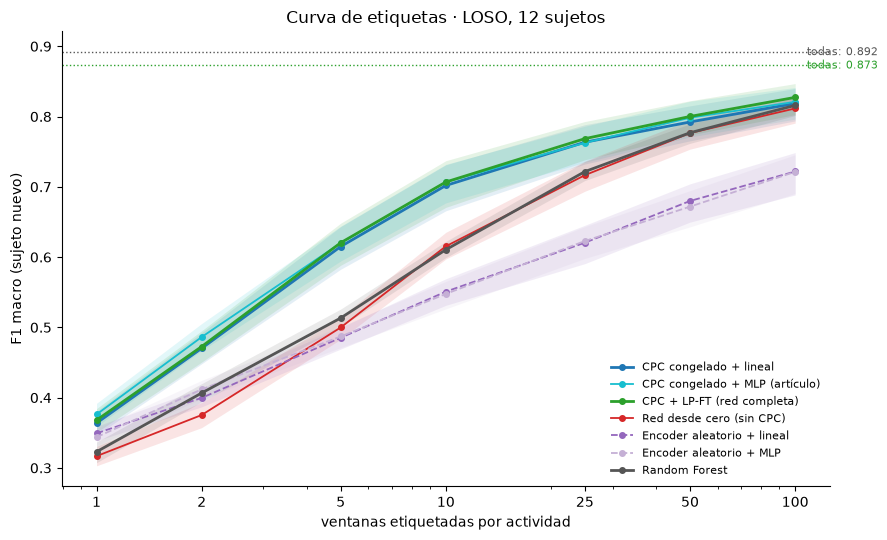

In [13]:
rows = [{"sujeto": s, "n": r["n"], "rep": r["rep"], "brazo": a, "f1": f}
        for s, st in results.items() for r in st["filas"] for a, f in r["f1"].items()]
df = pd.DataFrame(rows)
by_subject = df.groupby(["brazo", "n", "sujeto"])["f1"].mean()          # promedio de repeticiones por sujeto
SIZES = sorted(df["n"].unique())
subj_matrix = lambda arm: by_subject.loc[arm].unstack("sujeto").reindex(SIZES)   # (n, sujetos)

full = {"cpc_lpft": np.mean([json.loads((NB11_DIR / "gru_ft" / "EML" / f"ronda_s{s:02d}.json").read_text())["f1"] for s in FOLDS]),
        "rf": np.mean([json.loads((NB11_DIR / "rf" / "EML.json").read_text())["f1"][str(s)] for s in FOLDS])}
table = pd.DataFrame({ARMS[a]: subj_matrix(a).mean(axis=1) for a in ARMS}).T
table.columns.name = "ventanas por actividad"
table["todas (notebook 11)"] = [full.get(a, np.nan) for a in ARMS]
display(table.style.format("{:.3f}", na_rep="—").background_gradient(axis=None, cmap="Greens", subset=SIZES))


def bootstrap_ci(m, reps=2000, seed=SEED):
    """IC del 95 % de la media entre sujetos (columnas) para cada fila de `m`."""
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, m.shape[1], size=(reps, m.shape[1]))
    means = m.to_numpy()[:, idx].mean(axis=2)                          # (n, reps)
    return np.percentile(means, 2.5, axis=1), np.percentile(means, 97.5, axis=1)


STYLE = {"cpc_lineal": ("#1f77b4", "-"), "cpc_mlp": ("#17becf", "-"), "cpc_lpft": ("#2ca02c", "-"), "desde_cero": ("#d62728", "-"),
         "aleatorio_lineal": ("#9467bd", "--"), "aleatorio_mlp": ("#c5b0d5", "--"), "rf": ("#555555", "-")}
fig, ax = plt.subplots(figsize=(9, 5.5))
for arm, name in ARMS.items():
    m = subj_matrix(arm)
    lo, hi = bootstrap_ci(m)
    color, ls = STYLE[arm]
    ax.plot(SIZES, m.mean(axis=1), marker="o", ms=4, lw=2 if arm in ("cpc_lineal", "cpc_lpft", "rf") else 1.3, color=color, ls=ls, label=name)
    ax.fill_between(SIZES, lo, hi, color=color, alpha=0.12, lw=0)
for arm, value in full.items():
    ax.axhline(value, color=STYLE[arm][0], ls=":", lw=1)
    ax.text(SIZES[-1] * 1.08, value, f"todas: {value:.3f}", color=STYLE[arm][0], va="center", fontsize=8)
ax.set_xscale("log")
ax.set_xticks(SIZES, [str(n) for n in SIZES])
ax.set(xlabel="ventanas etiquetadas por actividad", ylabel="F1 macro (sujeto nuevo)", title="Curva de etiquetas · LOSO, 12 sujetos")
ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

## 8.2 ¿CPC le gana al Random Forest?

Para cada brazo CPC y cada tamaño: diferencia media de F1 contra el Random Forest, sujetos en los que CPC es mejor y prueba de Wilcoxon pareada por sujeto. La corrección de Holm se aplica a las 21 comparaciones juntas. La última columna aplica el criterio fijado en la introducción.

In [14]:
def paired_test(a, b):
    """Comparación pareada por sujeto de dos matrices (n, sujetos): diferencia media, sujetos que mejoran y p de Wilcoxon por fila."""
    out = []
    for n in SIZES:
        d = (a.loc[n] - b.loc[n]).to_numpy()
        p = wilcoxon(d).pvalue if np.any(d != 0) and len(d) > 1 else 1.0
        out.append({"n": n, "diferencia": d.mean(), "mejora en": int((d > 0).sum()), "de": len(d), "p": p})
    return out


def holm(p):
    """p ajustados por Holm-Bonferroni."""
    p = np.asarray(p, dtype=float)
    order = np.argsort(p)
    adj = np.empty_like(p)
    adj[order] = np.minimum(1, np.maximum.accumulate(p[order] * (len(p) - np.arange(len(p)))))
    return adj


def comparison_table(pairs):
    rows = [{"comparación": label, **r} for label, a, b in pairs for r in paired_test(subj_matrix(a), subj_matrix(b))]
    out = pd.DataFrame(rows)
    out["p (Holm)"] = holm(out["p"])
    min_wins = int(np.ceil(0.75 * out["de"].max()))                  # 9 de 12 sujetos
    out["¿mejor?"] = np.where((out["diferencia"] > 0) & (out["p (Holm)"] < 0.05) & (out["mejora en"] >= min_wins), "sí", "no")
    out["mejora en"] = out["mejora en"].astype(str) + " de " + out["de"].astype(str)
    return out.drop(columns="de").set_index(["comparación", "n"])


fmt = {"diferencia": "{:+.3f}", "p": "{:.4f}", "p (Holm)": "{:.4f}"}
vs_rf = comparison_table([(f"{ARMS[a]} − RF", a, "rf") for a in CPC_ARMS])
display(vs_rf.style.format(fmt))

## 8.3 ¿La ventaja es del preentrenamiento? Controles

Cada brazo CPC contra la misma red sin CPC:

- **CPC + LP-FT − red desde cero:** la misma arquitectura, entrenada con las mismas etiquetas; sólo cambia si parte del preentrenamiento.
- **CPC congelado − encoder aleatorio congelado,** con la misma cabeza: cuánto aporta lo que CPC aprendió.

Holm sobre las 21 comparaciones de esta tabla.

In [15]:
controls = comparison_table([("CPC + LP-FT − red desde cero", "cpc_lpft", "desde_cero"),
                             ("CPC + lineal − aleatorio + lineal", "cpc_lineal", "aleatorio_lineal"),
                             ("CPC + MLP − aleatorio + MLP", "cpc_mlp", "aleatorio_mlp")])
display(controls.style.format(fmt))

## 8.4 Eficiencia de etiquetas

¿Cuántas ventanas por actividad necesita el Random Forest para igualar el F1 que CPC logra con n? Se interpola la curva media del Random Forest en escala logarítmica. Un cociente de 4 significa que, para el mismo F1, el Random Forest necesita 4 veces más etiquetas.

In [16]:
rf_curve = np.maximum.accumulate(subj_matrix("rf").mean(axis=1).to_numpy())     # curva no decreciente para poder invertirla
log_sizes = np.log(SIZES)


def rf_equivalent(f1):
    if f1 <= rf_curve[0]:
        return f"≤ {SIZES[0]}", np.nan
    if f1 > rf_curve[-1]:
        return f"> {SIZES[-1]}", np.nan
    n_eq = float(np.exp(np.interp(f1, rf_curve, log_sizes)))
    return f"{n_eq:.0f}", n_eq


rows = []
for arm in CPC_ARMS:
    for n, f1 in subj_matrix(arm).mean(axis=1).items():
        label, n_eq = rf_equivalent(f1)
        rows.append({"brazo": ARMS[arm], "n": n, "F1 de CPC": f1, "el RF necesita (ventanas por actividad)": label,
                     "cociente": n_eq / n if np.isfinite(n_eq) else np.nan})
display(pd.DataFrame(rows).set_index(["brazo", "n"]).style.format({"F1 de CPC": "{:.3f}", "cociente": "{:.1f}"}, na_rep="—"))

## 8.5 Estabilidad

**Entre repeticiones:** desviación estándar del F1 entre las 10 muestras de etiquetas de un mismo sujeto, promediada entre sujetos. Mide cuánto depende el resultado de *cuáles* ventanas se etiquetaron. **Peor sujeto:** el mínimo entre sujetos del F1 medio.

In [17]:
spread = df.groupby(["brazo", "n", "sujeto"])["f1"].std().groupby(["brazo", "n"]).mean().unstack("n")
worst = by_subject.groupby(["brazo", "n"]).min().unstack("n")
for title, t in (("Desviación entre repeticiones", spread), ("Peor sujeto", worst)):
    t = t.reindex(list(ARMS)).rename(index=ARMS)
    t.columns.name = "ventanas por actividad"
    print(title)
    display(t.style.format("{:.3f}"))

Desviación entre repeticiones


ventanas por actividad,1,2,5,10,25,50,100
brazo,,,,,,,
CPC congelado + lineal,0.063,0.065,0.062,0.035,0.028,0.024,0.016
CPC congelado + MLP (artículo),0.065,0.067,0.062,0.036,0.026,0.023,0.016
CPC + LP-FT (red completa),0.065,0.068,0.063,0.037,0.028,0.025,0.016
Red desde cero (sin CPC),0.072,0.076,0.066,0.053,0.044,0.036,0.031
Encoder aleatorio + lineal,0.064,0.058,0.041,0.040,0.033,0.029,0.024
Encoder aleatorio + MLP,0.064,0.056,0.046,0.040,0.040,0.038,0.035
Random Forest,0.059,0.056,0.052,0.047,0.027,0.020,0.014


Peor sujeto


ventanas por actividad,1,2,5,10,25,50,100
brazo,,,,,,,
CPC congelado + lineal,0.317,0.397,0.487,0.578,0.664,0.702,0.728
CPC congelado + MLP (artículo),0.327,0.416,0.536,0.603,0.673,0.694,0.722
CPC + LP-FT (red completa),0.319,0.398,0.489,0.578,0.671,0.712,0.737
Red desde cero (sin CPC),0.271,0.316,0.438,0.551,0.615,0.683,0.721
Encoder aleatorio + lineal,0.311,0.350,0.430,0.478,0.503,0.552,0.583
Encoder aleatorio + MLP,0.302,0.365,0.437,0.461,0.526,0.544,0.587
Random Forest,0.261,0.381,0.475,0.578,0.696,0.716,0.748


## 8.6 Qué eligió la validación cruzada y cómo se detuvo CPC

- **Épocas de ajuste fino en LP-FT:** si la mediana es 0, la validación cruzada prefirió quedarse con la cabeza lineal, sin ajustar la red.
- **`C` de la cabeza lineal de CPC** y **épocas de la red desde cero.**
- **CPC sin etiquetas:** época elegida y pérdida InfoNCE en el sujeto de validación, por ronda.

In [18]:
params = pd.DataFrame([{"n": r["n"], "épocas LP-FT": r["params"]["cpc_lpft"]["epocas"], "C lineal CPC": r["params"]["cpc_lineal"]["C"],
                        "épocas desde cero": r["params"]["desde_cero"]["epocas"], "LR MLP CPC": r["params"]["cpc_mlp"]["lr"]}
                       for st in results.values() for r in st["filas"]])
summary = params.groupby("n").agg(**{
    "épocas LP-FT (mediana)": ("épocas LP-FT", "median"), "LP-FT con 0 épocas": ("épocas LP-FT", lambda e: (e == 0).mean()),
    "C lineal (más elegido)": ("C lineal CPC", lambda c: c.mode().iloc[0]), "épocas desde cero (mediana)": ("épocas desde cero", "median"),
    "LR MLP (más elegido)": ("LR MLP CPC", lambda c: c.mode().iloc[0])})
display(summary.style.format({"LP-FT con 0 épocas": "{:.0%}", "épocas LP-FT (mediana)": "{:.0f}", "épocas desde cero (mediana)": "{:.0f}",
                              "C lineal (más elegido)": "{:g}", "LR MLP (más elegido)": "{:g}"}))

cpc_info = pd.DataFrame({s: {"época elegida": st["cpc"]["best_epoch"], "InfoNCE val": st["cpc"]["val_info_nce"],
                             "InfoNCE val sin entrenar": st["cpc"]["curva"][0][1], "minutos": st["cpc"]["minutes"]}
                         for s, st in results.items()}).T.rename_axis("sujeto evaluado")
display(cpc_info.style.format({"época elegida": "{:.0f}", "InfoNCE val": "{:.3f}", "InfoNCE val sin entrenar": "{:.3f}", "minutos": "{:.1f}"}))

,épocas LP-FT (mediana),LP-FT con 0 épocas,C lineal (más elegido),épocas desde cero (mediana),LR MLP (más elegido)
n,,,,,
1,10,0%,1,30,0.0005
2,0,76%,0.01,17,0.0005
5,6,23%,10,32,0.0005
10,10,12%,0.1,45,0.0005
25,16,11%,1,41,0.0005
50,16,6%,0.1,43,0.0001
100,20,2%,1,44,0.0001


,época elegida,InfoNCE val,InfoNCE val sin entrenar,minutos
sujeto evaluado,,,,
1,16,2.307,4.852,1.7
2,20,1.696,4.852,1.7
3,20,1.721,4.852,1.7
4,20,1.786,4.852,1.7
5,20,1.622,4.852,1.7
6,20,1.795,4.852,1.7
7,20,2.229,4.852,1.7
8,20,1.707,4.852,1.7
9,20,2.003,4.852,1.7


## 8.7 F1 por actividad con pocas etiquetas

F1 de cada actividad con 10 ventanas por actividad (o el tamaño más cercano que se haya corrido), promediado entre repeticiones y sujetos.

In [19]:
N_DETAIL = min(SIZES, key=lambda n: abs(n - 10))
per_class = {a: np.mean([r["f1_clase"][a] for st in results.values() for r in st["filas"] if r["n"] == N_DETAIL], axis=0) for a in ARMS}
per_class = pd.DataFrame(per_class, index=pd.Index(LABELS, name="actividad")).rename(columns=ARMS)
print(f"{N_DETAIL} ventanas etiquetadas por actividad")
display(per_class.style.format("{:.3f}").background_gradient(axis=None, cmap="Greens"))

10 ventanas etiquetadas por actividad


,CPC congelado + lineal,CPC congelado + MLP (artículo),CPC + LP-FT (red completa),Red desde cero (sin CPC),Encoder aleatorio + lineal,Encoder aleatorio + MLP,Random Forest
actividad,,,,,,,
N,0.813,0.811,0.816,0.696,0.819,0.789,0.732
LF,0.712,0.723,0.713,0.634,0.449,0.450,0.705
K,0.693,0.710,0.697,0.659,0.619,0.636,0.437
PT,0.600,0.595,0.596,0.462,0.420,0.420,0.379
LT,0.560,0.555,0.568,0.398,0.352,0.340,0.437
W,0.830,0.828,0.836,0.732,0.737,0.738,0.822
PF,0.705,0.725,0.721,0.728,0.461,0.462,0.762


# 9. Conclusiones

**Respuesta corta:** sí. Con **10 ventanas etiquetadas por actividad o menos**, CPC-GRU supera al Random Forest en un sujeto nuevo:

- La diferencia es de **+0.04 a +0.11 de F1 macro** y aparece en 11 o 12 de los 12 sujetos (p con Holm < 0.02, en los tres brazos CPC).
- El máximo está entre 5 y 10 ventanas por actividad, donde CPC iguala al Random Forest usando **≈ 2.2 veces menos etiquetas**.
- La ventaja sale del preentrenamiento sin etiquetas, no de la arquitectura.
- Con 25 ventanas o más la ventaja se reduce y deja de ser significativa. Con todas las etiquetas el Random Forest es mejor: 0.892 contra 0.873 (notebook 11).

| ventanas por actividad | 1 | 2 | 5 | 10 | 25 | 50 | 100 | todas |
|---|---|---|---|---|---|---|---|---|
| CPC + LP-FT | 0.368 | 0.473 | **0.620** | **0.707** | 0.769 | 0.800 | 0.827 | 0.873 |
| Random Forest | 0.323 | 0.407 | 0.513 | 0.611 | 0.722 | 0.777 | 0.816 | 0.892 |
| diferencia | +0.045 | +0.066 | **+0.107** | **+0.096** | +0.047 | +0.023 | +0.011 | −0.019 |
| ¿significativa? (Holm) | sí | sí | sí | sí | no | no | no | — |

## 9.1 Dónde está la ventaja

- **Pocas etiquetas (1–10 por actividad, es decir 7–70 ventanas, menos del 0.2 % de las etiquetas de entrenamiento):**
  - Los tres brazos CPC le ganan al Random Forest en 11–12 de 12 sujetos, con p (Holm) entre 0.010 y 0.019.
  - La mayor diferencia está en 5 ventanas por actividad: +0.102 lineal, +0.107 MLP y +0.107 LP-FT.
- **Zona intermedia (25–50):**
  - CPC sigue arriba en promedio (+0.015 a +0.047) y en 10 de 12 sujetos.
  - Con la corrección por 21 comparaciones ya no es significativo (p Holm ≥ 0.24).
- **100 por actividad:**
  - Las curvas se juntan (+0.003 a +0.011, p Holm ≥ 0.26).
  - Con todas las etiquetas el orden se invierte, así que el cruce ocurre en algún punto entre 100 ventanas por actividad y el conjunto completo.
- **Eficiencia de etiquetas (8.4):**
  - Para igualar lo que CPC logra con 5 ventanas por actividad, el Random Forest necesita ≈ 11.
  - Para igualar lo que CPC logra con 10, necesita ≈ 22.
  - El cociente máximo es 2.2× y baja a 1.5× con 50.

## 9.2 La ventaja es del preentrenamiento CPC

Los dos controles aíslan el efecto del preentrenamiento:

- **Misma red entrenada desde cero:**
  - Queda prácticamente sobre la curva del Random Forest (0.615 contra 0.611 con 10 ventanas).
  - CPC + LP-FT le gana con significancia hasta 25 ventanas por actividad (+0.05 a +0.12, 11–12 de 12 sujetos).
  - La arquitectura sola no da ventaja; la da la inicialización con CPC.
- **Encoder aleatorio congelado:**
  - Con las mismas cabezas, CPC le gana por +0.07 a +0.16 desde 2 ventanas por actividad, en 12 de 12 sujetos.
  - Con 100 ventanas por actividad la diferencia sigue en +0.10.
  - Las representaciones que aprende CPC son las que separan las actividades, no la capacidad de la cabeza.

## 9.3 Cómo se usa CPC: basta congelarlo

Esto responde a la pregunta de si se ajusta solo el clasificador o la red completa:

- **Las tres formas de usar CPC dan casi lo mismo.**
  - Congelado + lineal, congelado + MLP del artículo y LP-FT (red completa) difieren en ≤ 0.016 en todos los tamaños.
  - El MLP del artículo es ligeramente mejor con 1–2 ventanas (+0.012 a +0.016 sobre el lineal).
  - LP-FT es ligeramente mejor con 50–100 (+0.008).
- **Ajustar la red completa casi no aporta.**
  - Con 2 ventanas por actividad, la validación cruzada eligió **0 épocas** de ajuste fino en el 76 % de los casos.
  - El número de épocas elegido crece con n (mediana 6 con n = 5 y 20 con n = 100), pero la ganancia nunca pasa de un punto.
- **Esto coincide con el protocolo del artículo de CPC para HAR:** encoder y GRU congelados, y solo se entrena el clasificador.
- **Recomendación práctica:** CPC congelado + cabeza lineal. Es lo más simple y rápido, y no se pierde nada relevante.

## 9.4 Estabilidad y los sujetos que no siguen la tendencia

- **Entre repeticiones:**
  - Con 1–5 ventanas por actividad, todas las variantes varían igual (desviación ≈ 0.06): domina qué ventanas tocaron.
  - Con 10, CPC es más estable que el Random Forest (0.035–0.037 contra 0.047) y que la red desde cero (0.053).
- **Sujeto 8:**
  - Es la excepción más clara: el Random Forest le gana a CPC desde 5 ventanas por actividad (−0.05 con 5 y 10, −0.08 a −0.09 con 25–100).
  - Con 5 y 10 ventanas es el sujeto con peor F1 de CPC.
- **Sujeto 2:**
  - El Random Forest también le gana con 25 o más ventanas por actividad (−0.01 a −0.03).
  - Desde 25 ventanas es el peor sujeto de ambos métodos, y por eso el peor sujeto del Random Forest queda arriba del de CPC (0.696 contra 0.671 con 25).
- **Qué significa:** la ventaja de CPC es consistente, pero no universal.

## 9.5 En qué actividades gana CPC (10 ventanas por actividad)

| actividad | CPC + LP-FT | Random Forest | diferencia |
|---|---|---|---|
| K | 0.697 | 0.437 | +0.26 |
| PT | 0.596 | 0.379 | +0.22 |
| LT | 0.568 | 0.437 | +0.13 |
| N | 0.816 | 0.732 | +0.08 |
| W | 0.836 | 0.822 | +0.01 |
| LF | 0.713 | 0.705 | +0.01 |
| PF | 0.721 | 0.762 | −0.04 |

- **Dónde gana:** la ventaja se concentra en K, PT y LT, las actividades que se distinguen por cómo evoluciona el movimiento y no por la postura promedio. Con pocos ejemplos, las estadísticas por ventana del Random Forest no alcanzan a describirlas.
- **Dónde empata o pierde:** en W y LF empatan, y en PF el Random Forest es mejor.

## 9.6 Limitaciones

- **El preentrenamiento CPC llegó al tope de 20 épocas** en 10 de 12 rondas: la pérdida InfoNCE de validación seguía bajando. Con más épocas, la ventaja podría ser algo mayor; no se probó.
- **El escenario es idealizado:**
  - Hay exactamente n ventanas por actividad, balanceadas, de los 10 sujetos de entrenamiento.
  - Un etiquetado real tendería a ser desbalanceado y a concentrarse en pocos sujetos.
- **Hay datos sin etiquetar de sobra:** CPC usa todas las ventanas de los 10 sujetos de entrenamiento. La ventaja supone que esos registros existen, aunque no estén etiquetados.

## 9.7 Qué significa para el proyecto

- **Es el argumento a favor de CPC-GRU.**
  - Con todas las etiquetas, el Random Forest es igual o mejor (notebooks 11 y 15).
  - Cuando etiquetar es caro (unas pocas decenas de ventanas por actividad), el preentrenamiento sin etiquetas da hasta 10 puntos de F1 en personas nuevas.
  - Equivale a necesitar ≈ la mitad de etiquetas.
- **Afirmación que se puede sostener:** *con hasta 10 ventanas etiquetadas por actividad, CPC-GRU preentrenado sin etiquetas supera al Random Forest en un sujeto nuevo, de forma estadísticamente significativa y en 11 de 12 sujetos; la ventaja se debe al preentrenamiento y desaparece a partir de ≈ 25–50 ventanas por actividad.*
- **Afirmación que no se puede sostener:** que CPC sea mejor en general. Con etiquetas abundantes no lo es.